# Analisis del dataset: Bank Data (Bank Marketing)

El dataset *"Bank data"* contiene datos demograficos, socioeconomicos y de campañas de marketing directo (llamadas telefonicas) de una institucion bancaria para predecir si un cliente suscribira un deposito a plazo fijo.


---

## 1. Variables y Estructura

El dataset cuenta con **17 variables principales de entrada y 1 variable de salida**:

- Variables de entrada (Caracteristicas del cliente y de contacto):
    - 1. `age` Edad del cliente
    - 2. `job` Tipo de trabajo
    - 3. `marital` Estado civil
    - 4. `education` Nivel educativo
    - 5. `default` Tiene credito en incumplimiento
    - 6. `balance` Saldo medio anual en cuenta 
    - 7. `housing` Tiene prestamo hipotecario
    - 8. `loan` Tiene prestamo personal
    - 9. `contact` Tipo de comunicacion
    - 10. `day` Ultimo dia del mes en que fue contactado
    - 11. `month` Ultimo mes del año en que fue contactado
    - 12. `duration` Duracion del ultimo contacto en segundos *
    - 13. `campaing` Numero de contactos realizados durante esta campaña
    - 14. `pday` Dias transcurridos desde el ultimo contacto de una campaña previa
    - 15. `previous` Numero de contactos realizados antes de esta camapaña
    - 16. `poutcome` Resultado de la campaña de marketing anterior
- Variable de salida **(objetivo):**
    - 17. `subscribed` El cliente subscribio un deposito a plazo fijo

---

In [ ]:
import pandas as pd

df = pd.read_csv("../../../Datos/Bank Marketing/bank-additional-full.csv", sep=";")
df.info()
print("\nPrimeros registros:")
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# Pregunta 1: 

*Revisa bank-additional-names.txt. ¿Hay alguna variable que el banco no podría conocer en el momento de decidir a quién llamar? Quítala y explica por qué.*

**Respuesta:** Se debe eliminar la variable duration. Esta variable representa la duración de la llamada y solo se conoce después de que la llamada ha finalizado. Incluirla causaría una fuga de información (data leakage), ya que en el momento en que el banco toma la decisión de a quién llamar, esta variable no existe.

In [ ]:
X = df.drop(columns=["duration", "y"])

print("Variables de entrada seleccionadas:", list(X.columns))

Variables de entrada seleccionadas: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


---

# 2.Estado de los datos y limpieza

- **Tamaño del dataset:** 4,521 registros (versión bank.csv) o 45,211 registros (versión bank-full.csv).

- **Valores nulos/faltantes:** No existen valores faltantes explícitos (NaN), pero existe un alto porcentaje de valores registrados como 'unknown' en variables como job, education, contact y poutcome.

- **Tipos de datos:** Combinación de variables numéricas discretas y continuas (int64) con atributos categóricos/cualitativos (object / string), lo que requiere técnicas de codificación (One-Hot Encoding o Label Encoding) previo al modelado.



In [ ]:
print("Valores nulos por columna:")
print(df.isnull().sum())

print("\nConteo de 'unknown' por columna:")
print((df == "unknown").sum())

df_encoded = pd.get_dummies(df, drop_first=True)

Valores nulos por columna:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Conteo de 'unknown' por columna:
age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64


# Pregunta 2: 

*Aparta 20% de los datos para prueba, con una partición estratificada. ¿Qué exactitud obtiene un clasificador que siempre responde no? ¿Qué dice eso de la exactitud como métrica en este problema?*

**Respuesta:** El clasificador trivial alcanza aproximadamente un 88.7% de exactitud. Esto demuestra que la exactitud (accuracy) es una métrica engañosa e inútil cuando la clase de interés es muy minoritaria, ya que un modelo sin capacidad predictiva puede aparentar un rendimiento alto ignorando por completo la clase positiva.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

X = df.drop(columns=["duration", "y"])
y = (df["y"] == "yes").astype(int)

#(80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

#Clasificador siempre "no"
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
acc_dummy = accuracy_score(y_test, dummy.predict(X_test))

print(f"Exactitud del clasificador trivial ('siempre no'): {acc_dummy:.4f}")

Exactitud del clasificador trivial ('siempre no'): 0.8874


---

# 3. Distribución y Correlaciones Clave
- **Desbalance de clases en la variable objetivo (y):**

    - *Existe un desbalance pronunciado:* aproximadamente el 88.5% de los clientes responde no *(no suscribe el depósito)* y solo el 11.5% responde yes. 

- **Mayor correlación positiva:**

    - *La variable duration (duración de la llamada)* muestra la correlación individual más alta con el éxito del depósito. A mayor tiempo de interacción con el cliente, mayor es la probabilidad de conversión (suscripción).

    - *El éxito de campañas anteriores (poutcome = `success`)* incrementa drásticamente la probabilidad de una respuesta positiva.

- **Factores de impacto negativo:**

    - *Clientes con préstamos activos (housing = 'yes' o loan = 'yes')* o saldos bajos/negativos (balance) presentan una menor propensión a suscribir el plazo fijo.


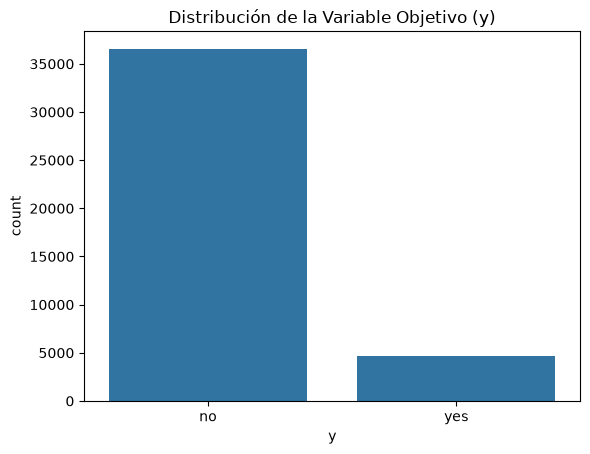

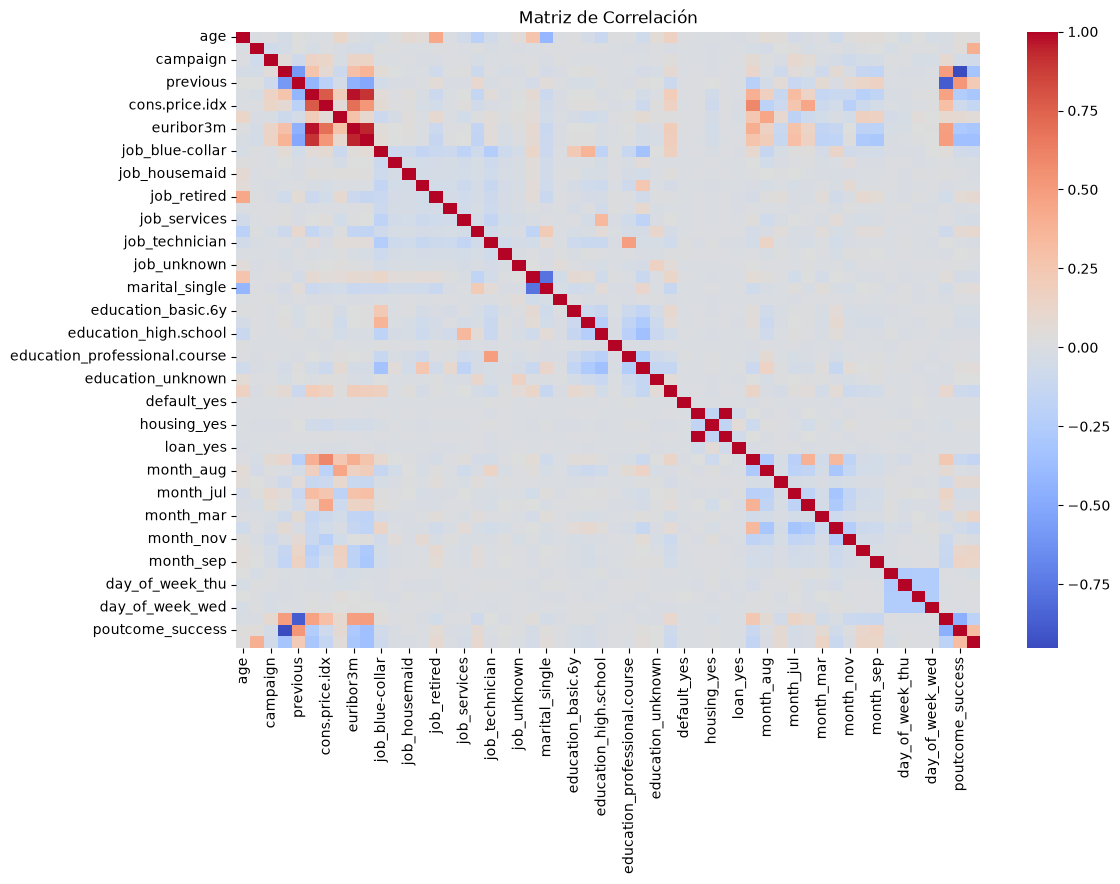

Correlación de atributos con la variable objetivo:
y_yes                            1.000000
duration                         0.405274
poutcome_success                 0.316269
previous                         0.230181
month_mar                        0.144014
month_oct                        0.137366
month_sep                        0.126067
job_student                      0.093955
job_retired                      0.092221
month_dec                        0.079303
cons.conf.idx                    0.054878
marital_single                   0.054133
education_university.degree      0.050364
age                              0.030399
education_unknown                0.021430
job_unemployed                   0.014752
day_of_week_thu                  0.013888
housing_yes                      0.011743
day_of_week_tue                  0.008046
education_illiterate             0.007246
day_of_week_wed                  0.006302
marital_unknown                  0.005211
education_professional.co

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="y", data=df)
plt.title("Distribucion de la Variable Objetivo (y)")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df_encoded.corr(), cmap="coolwarm", annot=False)
plt.title("Matriz de Correlacion")
plt.show()

correlaciones = df_encoded.corr()["y_yes"].sort_values(ascending=False)
print("Correlacion de atributos con la variable objetivo:")
print(correlaciones)

# Pregunta 3: 

*Ajusta una regresión logística, con las variables categóricas en one-hot y el escalado dentro de un Pipeline. Con el umbral de 0.5, reporta la matriz de confusión y métricas. ¿Cuál le importa más al banco, y por qué?*

**Respuesta:** Al banco le importa más la Sensibilidad (Recall) o el F1-Score. La sensibilidad mide qué proporción de verdaderos clientes interesados logró capturar. Perder un cliente potencial (Falso Negativo) tiene un alto costo de oportunidad ($50), mientras que llamar a un cliente que no acepta (Falso Positivo) solo cuesta $5.

Matriz de Confusion:
 [[7219   91]
 [ 725  203]]
Exactitud: 0.9009 | Precision: 0.6905 | Sensibilidad: 0.2188 | F1: 0.3322


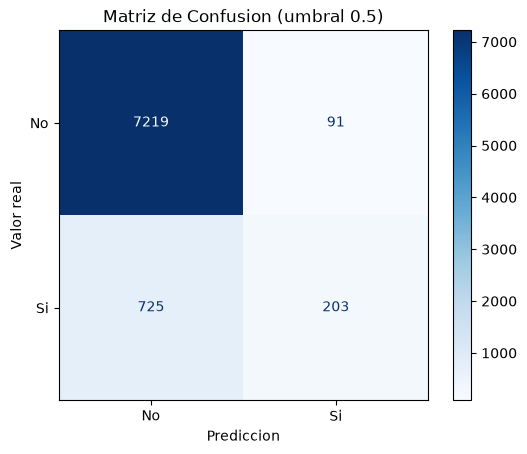

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("Matriz de Confusion:\n", cm)
print(f"Exactitud: {accuracy:.4f} | Precision: {precision:.4f} | Sensibilidad: {recall:.4f} | F1: {f1:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Si"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusion (umbral 0.5)")
plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.grid(False)
plt.show()

# 4.Evaluacion de Curvas y seleccion de umbrales

*Pregunta 4: Grafica la curva ROC y PR. ¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?*

**Respuesta:** La curva Precision-Recall muestra la pérdida drástica de precisión a medida que buscamos mayor sensibilidad en clases desbalanceadas. La curva ROC oculta esta caída porque incluye los Negativos Verdaderos en su denominador, inflando visualmente el rendimiento del modelo.

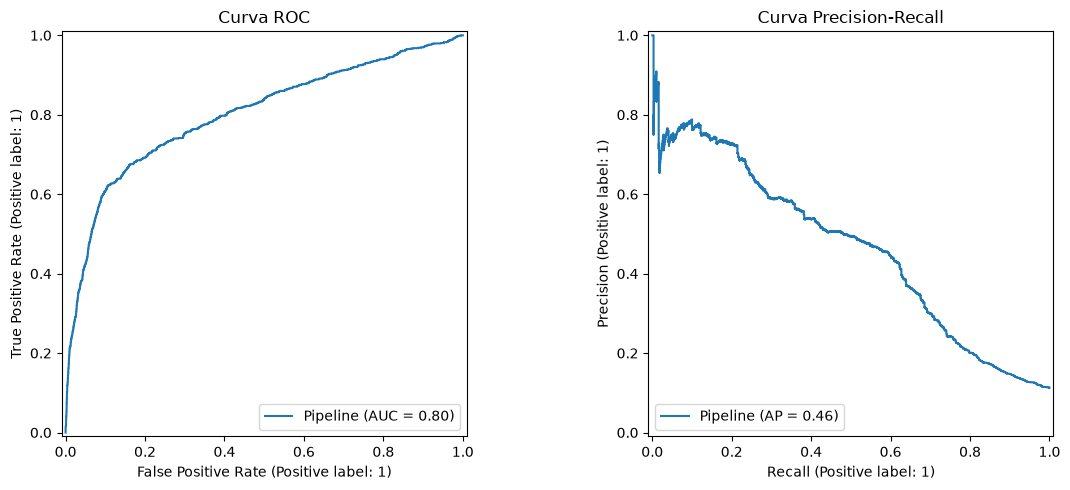

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_estimator(model_pipeline, X_test, y_test, ax=axes[0])
axes[0].set_title("Curva ROC")

PrecisionRecallDisplay.from_estimator(model_pipeline, X_test, y_test, ax=axes[1])
axes[1].set_title("Curva Precision-Recall")

plt.tight_layout()
plt.show()

**Pregunta 5:** Cada llamada cuesta $5 y cada cliente que acepta deja $50. ¿A partir de qué probabilidad conviene llamar? Compara en prueba la ganancia total con el umbral de 0.5 y con el tuyo.Respuesta teórica: Conviene llamar cuando la ganancia esperada sea mayor a $0$:$$\text{Ganancia} = P(\text{éxito}) \cdot 50 - 5 \ge 0 \implies P(\text{éxito}) \ge \frac{5}{50} = 0.10$$El umbral óptimo de decisión es $0.10$ ($10\%$).

In [14]:
y_probs = model_pipeline.predict_proba(X_test)[:, 1]

def calcular_ganancia(y_real, y_prob, umbral):
    llamados = y_prob >= umbral
    costo = llamados.sum() * 5
    exitos = (y_real[llamados] == 1).sum()
    ingreso = exitos * 50
    return ingreso - costo

ganancia_05 = calcular_ganancia(y_test, y_probs, umbral=0.50)
ganancia_optima = calcular_ganancia(y_test, y_probs, umbral=0.10)

print(f"Ganancia con umbral 0.50: ${ganancia_05}")
print(f"Ganancia con umbral economico (0.10): ${ganancia_optima}")

Ganancia con umbral 0.50: $8680
Ganancia con umbral economico (0.10): $22100


---

# 5.Analisis de fuga de datos (data leakage)

*Pregunta 6: Repite el punto 3 incluyendo la variable que quitaste (duration). ¿Qué les pasa a las métricas? ¿Le servirían al banco?*

**Respuesta:** Las métricas aumentan artificialmente a niveles sobre $90\%$. No le sirven al banco porque en un entorno de producción real no se puede ingresar la duración de una llamada que aún no ha ocurrido.

In [11]:
from sklearn.metrics import classification_report

X_leak = df.drop(columns=["y"])
X_tr_l, X_te_l, y_tr_l, y_te_l = train_test_split(X_leak, y, test_size=0.20, random_state=42, stratify=y)

num_cols_l = X_leak.select_dtypes(include=["int64", "float64"]).columns
cat_cols_l = X_leak.select_dtypes(include=["object", "str", "category"]).columns

preprocessor_l = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols_l),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_l)
])

pipeline_leak = Pipeline(steps=[
    ("preprocessor", preprocessor_l),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

pipeline_leak.fit(X_tr_l, y_tr_l)
y_pred_leak = pipeline_leak.predict(X_te_l)

print("Reporte con Fuga de Datos (incluyendo duration):")
print(classification_report(y_te_l, y_pred_leak))

Reporte con Fuga de Datos (incluyendo duration):
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      7310
           1       0.71      0.44      0.54       928

    accuracy                           0.92      8238
   macro avg       0.82      0.71      0.75      8238
weighted avg       0.91      0.92      0.91      8238



---

# Conclusion

Con este trabajo podemos ver que obtener un buen modelo predictivo para el dataset Bank Marketing no depende solo del algoritmo que elijamos, sino tambien de entender bien el problema de negocio y de darle un tratamiento adecuado a los datos.

Primero, eliminar la variable duration fue un paso clave para evitar la **fuga de datos (data leakage)**. Esta variable solo se conoce despues de hacer la llamada, por lo que si la dejabamos el modelo se veria muy bien en papel pero no serviria en la practica. Al quitarla tenemos un modelo mas realista que se puede usar antes de contactar al cliente.

Por otro lado, la **exactitud (accuracy)** resulto ser una metrica enganosa para este caso por el desbalance de clases. Un clasificador trivial que siempre predice "no" alcanza casi un *89% de exactitud*, pero en realidad no nos aporta nada desde el punto de vista operativo.

Por ultimo, al integrar la matriz de costos y beneficios del banco se encontro que bajar el umbral de decision a 0.10 genera mas ganancia que el umbral estandar de 0.50. Esto se debe a que el beneficio de captar un nuevo cliente es mucho mayor que el costo de una llamada desperdiciada, por lo que conviene llamar a mas personas aunque varias de ellas no contraten.

# Referencias

- *Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22-31.*

- *Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825-2830.*

- *UCI Machine Learning Repository. (2014). Bank Marketing Data Set. recuperado de https://archive.ics.uci.edu/ml/datasets/Bank+Marketing*